# 18 · Đánh Giá Toàn Diện Baseline B0 (YOLOv8s) Trên Tập Test PKU-Market-PCB
**Khóa Luận Tốt Nghiệp: Hệ Thống Nhận Diện & Đánh Giá Khuyết Tật Bo Mạch In (PCB Defect Detection)**

---

### 📌 Bối cảnh & Mục tiêu Đánh giá
Notebook này thực hiện quy trình đánh giá khoa học và độc lập cho mô hình Baseline **B0_yolov8s_100ep_batch16** (YOLOv8s, imgsz=1024, 100 epochs, batch=16) đã được huấn luyện trên Kaggle GPU (file `scripts/17-train-b0-yolov8s.ipynb` hoặc `scripts/17_train_B0_yolo11s_batch8_kaggle.ipynb`).

Mục tiêu chính:
1. **Kiểm thử khách quan (Zero Data Leakage)**: Đánh giá duy nhất trên tập Test (480 ảnh) hoàn toàn độc lập, tách nhóm bo mạch (Group-aware split) chống rò rỉ dữ liệu.
2. **Quy chuẩn đánh giá quốc tế (COCO Protocol)**: Sử dụng các chỉ số $mAP_{50}$, $mAP_{50-95}$, Mean Precision, Mean Recall, F1-Score trên 6 lớp khuyết tật vi mạch PCB.
3. **Quản lý thư mục độc lập**: Toàn bộ kết quả thực nghiệm B0 YOLOv8s được lưu tập trung vào thư mục riêng `evaluation/B0_yolov8s/`, bảo tồn nguyên vẹn kết quả của các mô hình khác (như B0 YOLO11s tại `evaluation/B0/`).
4. **Kiểm chứng trực quan (Qualitative Inspection)**: Đánh giá khả năng phát hiện lỗi thực tế ở ngưỡng triển khai ($conf=0.25, iou=0.7$) trên ảnh bo mạch nguyên bản.
5. **Khả năng tương thích kép**: Tự động nhận diện và chạy mượt mà trên cả **Kaggle Cloud GPU** và **Máy Local** (Mac/Linux/Windows).

---

### 🗺️ Lộ trình thực hiện qua các Phase:
- **Phase 0: Khởi Tạo Môi Trường & Kiểm Tra Checkpoint (Setup & Discovery)**
- **Phase 1: Chuẩn Bị & Xác Thực Dữ Liệu Kiểm Thử (Test Split Verification)**
- **Phase 2: Đánh Giá Định Lượng Trên Tập Test (Quantitative Evaluation)**
- **Phase 3: Báo Cáo Chi Tiết Từng Lớp Khuyết Tật (Per-Class Performance)**
- **Phase 4: Trực Quan Hóa Biểu Đồ Hiệu Năng (Performance Visualizations)**
- **Phase 5: Kiểm Chứng Dự Đoán Trực Quan Trên Bo Mạch Thực Tế (Qualitative Inspection)**
- **Phase 6: Phân Tích Chuyên Sâu, Định Hướng Cải Tiến & Đóng Gói (Discussion & Export)**


---
## Phase 0: Khởi Tạo Môi Trường & Kiểm Tra Checkpoint (Setup & Discovery)
*Mục tiêu: Nạp các thư viện khoa học dữ liệu, tự động phát hiện phần cứng (GPU/MPS/CPU), và định vị file trọng số `best.pt` của mô hình B0 YOLOv8s.*


In [6]:
# Cell 1 — Import các thư viện phân tích, đo lường và hiển thị
import os, sys, json, time, shutil, zipfile, hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import yaml
from IPython.display import display, FileLink
from ultralytics import YOLO

# Thiết lập thẩm mỹ trực quan cho đồ thị
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

print("✅ Thư viện phân tích & trực quan hoá đã sẵn sàng:")
print(f"   Python version     : {sys.version.split()[0]}")
print(f"   PyTorch version    : {torch.__version__}")
try:
    import ultralytics
    print(f"   Ultralytics version: {ultralytics.__version__}")
except Exception:
    pass


✅ Thư viện phân tích & trực quan hoá đã sẵn sàng:
   Python version     : 3.13.5
   PyTorch version    : 2.14.0
   Ultralytics version: 8.4.153


In [7]:
# Cell 2 — Tự động nhận diện môi trường (Kaggle GPU vs Local) & Định vị Checkpoint best.pt

IS_KAGGLE = Path("/kaggle").exists()

if IS_KAGGLE:
    ROOT_DIR = Path("/kaggle/working")
    WORK_DIR = Path("/kaggle/working")
    KAGGLE_IMG_ROOT = Path("/kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)")
    if not KAGGLE_IMG_ROOT.exists():
        candidates = [p for p in Path("/kaggle/input").rglob("PKU-Market-PCB(Data enhanced version)")
                      if (p/"train/images").is_dir() or (p/"test/images").is_dir()]
        if candidates:
            KAGGLE_IMG_ROOT = candidates[0]
            
    # Tìm kiếm code bundle nếu có
    CODE_ROOT = None
    for candidate in Path("/kaggle/input").rglob("base.yaml"):
        if candidate.parent.name == "configs":
            CODE_ROOT = candidate.parent.parent
            break
            
    DEVICE = 0 if torch.cuda.is_available() else "cpu"
    ENV_DESC = f"Kaggle Cloud (GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'})"
else:
    current = Path.cwd()
    ROOT_DIR = current.parent if current.name == "scripts" else current
    WORK_DIR = ROOT_DIR
    CODE_ROOT = ROOT_DIR
    KAGGLE_IMG_ROOT = ROOT_DIR / "data" / "raw" / "PKU-Market-PCB(Data enhanced version)"
    
    if torch.cuda.is_available():
        DEVICE = 0
        ENV_DESC = f"Local Machine (NVIDIA GPU: {torch.cuda.get_device_name(0)})"
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        DEVICE = "mps"
        ENV_DESC = "Local Machine (Apple Silicon MPS)"
    else:
        DEVICE = "cpu"
        ENV_DESC = "Local Machine (CPU)"

print(f"🌐 Môi trường thực thi: {ENV_DESC}")
print(f"📂 Thư mục làm việc  : {WORK_DIR}")

# ── Định vị checkpoint B0 YOLOv8s best.pt ─────────────────────────────────────
checkpoint_candidates = [
    WORK_DIR / "runs" / "B0_yolov8s_100ep_batch16" / "weights" / "best.pt",
    WORK_DIR / "experiences" / "B0_yolov8s_100ep_batch16" / "weights" / "best.pt",
    WORK_DIR / "runs" / "B0_yolov8s_100ep" / "weights" / "best.pt",
    WORK_DIR / "experiences" / "B0_yolov8s_100ep" / "weights" / "best.pt",
]

if IS_KAGGLE:
    checkpoint_candidates.extend(list(Path("/kaggle/working").rglob("best.pt")))
    checkpoint_candidates.extend(list(Path("/kaggle/input").rglob("best.pt")))

best_checkpoint = None
for candidate in checkpoint_candidates:
    if candidate.is_file():
        best_checkpoint = candidate
        break

if best_checkpoint is None:
    any_best = [p for p in WORK_DIR.rglob("best.pt") if "v8" in str(p).lower() or "batch16" in str(p).lower()]
    if any_best:
        best_checkpoint = any_best[0]
    else:
        any_best = list(WORK_DIR.rglob("best.pt"))
        if any_best:
            best_checkpoint = any_best[0]

assert best_checkpoint is not None and best_checkpoint.is_file(), (
    "❌ Không tìm thấy checkpoint best.pt của B0 YOLOv8s! Hãy kiểm tra runs/B0_yolov8s_100ep_batch16/weights/."
)

chk_size_mb = best_checkpoint.stat().st_size / (1024 * 1024)
chk_sha = hashlib.sha256(best_checkpoint.read_bytes()).hexdigest()[:12]
print(f"\n🎯 Checkpoint tìm thấy : {best_checkpoint}")
print(f"   Dung lượng          : {chk_size_mb:.2f} MB")
print(f"   SHA256 (prefix)     : {chk_sha}")

# ── Nạp metadata huấn luyện từ notebook 17 (nếu có) ─────────────────────────
metadata_candidates = [
    best_checkpoint.parent.parent / "run_metadata.json",
    WORK_DIR / "experiences" / "B0_yolov8s_100ep_batch16" / "run_metadata.json",
    WORK_DIR / "runs" / "B0_yolov8s_100ep_batch16" / "run_metadata.json",
    WORK_DIR / "evaluation" / "B0_yolov8s" / "run_metadata.json",
]
metadata = None
for m_path in metadata_candidates:
    if m_path.is_file():
        try:
            metadata = json.loads(m_path.read_text(encoding="utf-8"))
            print(f"\n📋 Đã nạp metadata huấn luyện ({m_path.name}):")
            print(f"   Experiment : {metadata.get('experiment_name')}")
            print(f"   Mô hình    : {metadata.get('model')} ({metadata.get('architecture')})")
            print(f"   Epochs     : {metadata.get('epochs')} | Imgsz: {metadata.get('imgsz')} | Batch: {metadata.get('batch')}")
            print(f"   mAP50 (val): {metadata.get('map50', 0):.4f} | mAP50-95 (val): {metadata.get('map50_95', 0):.4f}")
            break
        except Exception:
            pass


🌐 Môi trường thực thi: Local Machine (Apple Silicon MPS)
📂 Thư mục làm việc  : /Users/duytan/orca/projects/PCB-DetectionImprove

🎯 Checkpoint tìm thấy : /Users/duytan/orca/projects/PCB-DetectionImprove/runs/B0_yolov8s_100ep_batch16/weights/best.pt
   Dung lượng          : 21.56 MB
   SHA256 (prefix)     : 2b0ec7abf64a

📋 Đã nạp metadata huấn luyện (run_metadata.json):
   Experiment : B0_yolov8s_100ep_batch16
   Mô hình    : yolov8s.pt (YOLOv8s standard P3/P4/P5 (CSPDarknet))
   Epochs     : 100 | Imgsz: 1024 | Batch: 16
   mAP50 (val): 0.8381 | mAP50-95 (val): 0.4168


---
## Phase 1: Chuẩn Bị & Xác Thực Dữ Liệu Kiểm Thử (Test Split Verification)
*Mục tiêu: Đọc danh sách 480 ảnh test độc lập, xác thực đường dẫn vật lý và tạo file cấu hình dữ liệu `eval_data.yaml` chuẩn hóa theo quy chuẩn Ultralytics.*


In [8]:
# Cell 3 — Định vị split test.txt, tạo thư mục riêng evaluation/B0_yolov8s/ & sinh eval_data.yaml

split_file_candidates = [
    ROOT_DIR / "data" / "splits" / "test.txt",
    ROOT_DIR / "data" / "splits" / "test_kaggle.txt",
]
if CODE_ROOT:
    split_file_candidates.insert(0, CODE_ROOT / "data" / "splits" / "test.txt")
    split_file_candidates.insert(1, CODE_ROOT / "data" / "splits" / "test_kaggle.txt")

test_split_path = None
for cand in split_file_candidates:
    if cand and cand.is_file():
        test_split_path = cand
        break

assert test_split_path is not None, "❌ Không tìm thấy file split test.txt!"

LOCAL_PREFIX = "data/raw/PKU-Market-PCB(Data enhanced version)/"

def resolve_test_paths(txt_file: Path, img_root: Path, root_dir: Path) -> list:
    lines = txt_file.read_text(encoding="utf-8").strip().splitlines()
    resolved = []
    
    # Tìm kiếm các vị trí có thể có ảnh trên local machine
    alt_local_dirs = [
        Path("/Users/duytan/orca/projects/PCB-Detect/PKU-Market-PCB(Data enhanced version)"),
        Path("/Users/duytan/orca/projects/PCB-Defect/data/processed/PKU-Market-PCB"),
        root_dir / "data" / "raw" / "PKU-Market-PCB(Data enhanced version)"
    ]
    
    for line in lines:
        line = line.strip()
        if not line:
            continue
        p = Path(line)
        if p.is_file():
            resolved.append(str(p.resolve()))
            continue
        if (root_dir / line).is_file():
            resolved.append(str((root_dir / line).resolve()))
            continue
            
        # Trích xuất đường dẫn tương đối (ví dụ: train/images/xxx.jpg)
        rel = None
        if line.startswith(LOCAL_PREFIX):
            rel = line[len(LOCAL_PREFIX):]
        elif "PKU-Market-PCB(Data enhanced version)/" in line:
            rel = line.split("PKU-Market-PCB(Data enhanced version)/")[1]
        else:
            for key in ["train/images/", "valid/images/", "test/images/"]:
                if key in line:
                    rel = key + line.split(key)[-1]
                    break
        
        found = False
        if rel:
            for alt_dir in alt_local_dirs + [img_root]:
                target = alt_dir / rel
                if target.is_file():
                    resolved.append(str(target.resolve()))
                    found = True
                    break
                    
        if not found:
            # Fallback an toàn: không bao giờ nhân đôi LOCAL_PREFIX
            if rel:
                resolved.append(str((img_root / rel).resolve()))
            else:
                resolved.append(str((root_dir / line).resolve()))
                
    return resolved

test_image_paths = resolve_test_paths(test_split_path, KAGGLE_IMG_ROOT, ROOT_DIR)
existing_count = sum(1 for p in test_image_paths if Path(p).is_file())

print(f"📄 Nguồn split test     : {test_split_path}")
print(f"📊 Tổng số ảnh khai báo : {len(test_image_paths)}")
print(f"✅ Ảnh tồn tại thực tế  : {existing_count}/{len(test_image_paths)}")

if existing_count < len(test_image_paths):
    missing_samples = [p for p in test_image_paths if not Path(p).is_file()][:3]
    if not IS_KAGGLE:
        print(f"⚠️ Chú ý: Thiếu {len(test_image_paths) - existing_count} ảnh test.")
    else:
        raise FileNotFoundError(f"Thiếu {len(test_image_paths) - existing_count} ảnh test! Ví dụ: {missing_samples}")

# ── THIẾT LẬP THƯ MỤC ĐÁNH GIÁ RIÊNG CHO THỰC NGHIỆM B0 YOLOv8s ──────────────
EXP_NAME = "B0_yolov8s"
EVAL_DIR = WORK_DIR / "evaluation" / EXP_NAME
EVAL_DIR.mkdir(parents=True, exist_ok=True)

EVAL_SPLIT_FILE = EVAL_DIR / "test_eval_split.txt"
EVAL_SPLIT_FILE.write_text("\n".join(test_image_paths) + "\n", encoding="utf-8")

CLASSES = [
    "Missing_hole",
    "Mouse_bite",
    "Open_circuit",
    "Short",
    "Spur",
    "Spurious_copper"
]

# Ultralytics yêu cầu cả hai key 'train' và 'val' trong data YAML
eval_yaml_content = {
    "path": str(WORK_DIR),
    "train": str(EVAL_SPLIT_FILE.resolve()),
    "val": str(EVAL_SPLIT_FILE.resolve()),
    "test": str(EVAL_SPLIT_FILE.resolve()),
    "nc": len(CLASSES),
    "names": {i: name for i, name in enumerate(CLASSES)}
}

EVAL_YAML_PATH = EVAL_DIR / "eval_data.yaml"
with open(EVAL_YAML_PATH, "w", encoding="utf-8") as f:
    yaml.dump(eval_yaml_content, f, default_flow_style=False, allow_unicode=True)

print(f"📁 Thư mục lưu kết quả B0 YOLOv8s: {EVAL_DIR}")
print(f"✅ Cấu hình kiểm thử YAML       : {EVAL_YAML_PATH}")


📄 Nguồn split test     : /Users/duytan/orca/projects/PCB-DetectionImprove/data/splits/test.txt
📊 Tổng số ảnh khai báo : 480
✅ Ảnh tồn tại thực tế  : 480/480
📁 Thư mục lưu kết quả B0 YOLOv8s: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s
✅ Cấu hình kiểm thử YAML       : /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/eval_data.yaml


In [9]:
# Cell 4 — Thống kê phân bố Ground Truth Bounding Boxes trên 480 ảnh Test

gt_counts = {name: 0 for name in CLASSES}
total_boxes = 0

for img_p in test_image_paths:
    img_path = Path(img_p)
    parts = list(img_path.parts)
    if "images" in parts:
        idx = parts.index("images")
        parts[idx] = "labels"
        label_p = Path(*parts).with_suffix(".txt")
    else:
        label_p = img_path.parent.parent / "labels" / f"{img_path.stem}.txt"
        
    if label_p.is_file():
        lines = label_p.read_text(encoding="utf-8").strip().splitlines()
        for line in lines:
            line = line.strip()
            if not line:
                continue
            cid = int(line.split()[0])
            if 0 <= cid < len(CLASSES):
                gt_counts[CLASSES[cid]] += 1
                total_boxes += 1

gt_df = pd.DataFrame([
    {"Lớp khuyết tật (Class)": name, "Số lượng nhãn GT": count, "Tỷ lệ (%)": f"{count / max(1, total_boxes) * 100:.2f}%"}
    for name, count in gt_counts.items()
])

print(f"📊 PHÂN BỐ GROUND TRUTH ({total_boxes} boxes trên {len(test_image_paths)} ảnh Test):")
display(gt_df)


📊 PHÂN BỐ GROUND TRUTH (2424 boxes trên 480 ảnh Test):


,Lớp khuyết tật (Class),Số lượng nhãn GT,Tỷ lệ (%)
0,Missing_hole,408,16.83%
1,Mouse_bite,400,16.50%
2,Open_circuit,404,16.67%
3,Short,404,16.67%
4,Spur,404,16.67%
5,Spurious_copper,404,16.67%


---
## Phase 2: Đánh Giá Định Lượng Trên Tập Test (Quantitative Evaluation)
*Mục tiêu: Nạp checkpoint `best.pt` của YOLOv8s vào mô hình Ultralytics và thực thi đánh giá kiểm thử không qua huấn luyện lại (Strict Zero-Shot Test Evaluation).*


In [10]:
# Cell 5 — Khởi tạo mô hình YOLOv8s và thực thi đánh giá kiểm thử trên Test Split

print(f"🚀 Nạp mô hình từ checkpoint: {best_checkpoint}")
model = YOLO(str(best_checkpoint))

IMGSZ = int(metadata.get("imgsz", 1024)) if metadata else 1024
# Điều chỉnh batch size phù hợp tài nguyên: batch 16 cho GPU, batch 8 cho MPS/CPU để mượt mà
BATCH = int(metadata.get("batch", 16)) if DEVICE == 0 else 8

print("\n⚙️  Bắt đầu chạy đánh giá chuẩn COCO trên tập Test:")
print(f"   Mô hình     : YOLOv8s (CSPDarknet Backbone + Decoupled Head)")
print(f"   Kích thước  : {IMGSZ}x{IMGSZ}")
print(f"   Batch size  : {BATCH}")
print(f"   Thiết bị    : {DEVICE}")

eval_start = time.time()
val_results = model.val(
    data        = str(EVAL_YAML_PATH),
    imgsz       = IMGSZ,
    batch       = BATCH,
    split       = "val",
    project     = str(EVAL_DIR / "runs"),
    name        = "test_eval",
    device      = DEVICE,
    plots       = True,
    save_json   = False,
    verbose     = True
)
eval_elapsed = time.time() - eval_start
print(f"\n⏱️  Thời gian đánh giá: {eval_elapsed:.1f}s ({eval_elapsed/max(1, len(test_image_paths))*1000:.1f} ms/ảnh)")

# ── Thu thập chỉ số toàn diện ────────────────────────────────────────────────
box_metrics = val_results.box
map50    = float(box_metrics.map50)
map75    = float(box_metrics.map75)
map50_95 = float(box_metrics.map)
mp       = float(box_metrics.mp)
mr       = float(box_metrics.mr)
f1_mean = (2 * mp * mr / (mp + mr + 1e-16)) if (mp + mr) > 0 else 0.0

overall_metrics = {
    "experiment": EXP_NAME,
    "architecture": "YOLOv8s",
    "split": "test",
    "test_images": len(test_image_paths),
    "total_gt_boxes": total_boxes,
    "checkpoint": str(best_checkpoint.name),
    "checkpoint_sha256": chk_sha,
    "evaluated_at": datetime.now(timezone.utc).isoformat(),
    "imgsz": IMGSZ,
    "precision_mean": round(mp, 4),
    "recall_mean": round(mr, 4),
    "f1_score_mean": round(f1_mean, 4),
    "mAP50": round(map50, 4),
    "mAP75": round(map75, 4),
    "mAP50_95": round(map50_95, 4),
}

summary_df = pd.DataFrame([{
    "Tập Đánh Giá": "PKU Test (480 ảnh)",
    "Thực Nghiệm": EXP_NAME,
    "Mô Hình": "YOLOv8s",
    "Kích Thước": f"{IMGSZ}x{IMGSZ}",
    "mAP@0.5": f"{map50*100:.2f}%",
    "mAP@0.5:0.95": f"{map50_95*100:.2f}%",
    "Precision": f"{mp*100:.2f}%",
    "Recall": f"{mr*100:.2f}%",
    "F1-Score": f"{f1_mean*100:.2f}%"
}])

print("\n🏆 KẾT QUẢ TỔNG HỢP BASELINE B0 (YOLOv8s) TRÊN TẬP TEST:")
display(summary_df)


🚀 Nạp mô hình từ checkpoint: /Users/duytan/orca/projects/PCB-DetectionImprove/runs/B0_yolov8s_100ep_batch16/weights/best.pt

⚙️  Bắt đầu chạy đánh giá chuẩn COCO trên tập Test:
   Mô hình     : YOLOv8s (CSPDarknet Backbone + Decoupled Head)
   Kích thước  : 1024x1024
   Batch size  : 8
   Thiết bị    : mps
Ultralytics 8.4.153 🚀 Python-3.13.5 torch-2.14.0 MPS (Apple M1 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1911.5±755.6 MB/s, size: 1715.8 KB)
val: Scanning /Users/duytan/orca/projects/PCB-Detect/PKU-Market-PCB(Data enhanced version)/train/labels.cache... 480 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 480/480 154.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 1.4it/s 43.9s0.5ss
                   all        480       2424      0.844      0.921      0.877      0.416
          Missing_hole         80        

,Tập Đánh Giá,Thực Nghiệm,Mô Hình,Kích Thước,mAP@0.5,mAP@0.5:0.95,Precision,Recall,F1-Score
0,PKU Test (480 ảnh),B0_yolov8s,YOLOv8s,1024x1024,87.75%,41.57%,84.43%,92.07%,88.08%


---
## Phase 3: Báo Cáo Chi Tiết Từng Lớp Khuyết Tật (Per-Class Performance Breakdown)
*Mục tiêu: Bóc tách chỉ số cụ thể cho từng loại khuyết tật (Precision, Recall, F1, mAP50, mAP50-95) và lưu kết quả vào thư mục riêng `evaluation/B0_yolov8s/`.*


In [11]:
# Cell 6 — Trích xuất bảng chỉ số chi tiết 6 lớp lỗi và lưu trữ vào evaluation/B0_yolov8s/

observed_cids = [int(i) for i in box_metrics.ap_class_index]
per_class_rows = []

for cid in range(len(CLASSES)):
    c_name = CLASSES[cid]
    if cid in observed_cids:
        pos = observed_cids.index(cid)
        c_p = float(box_metrics.p[pos])
        c_r = float(box_metrics.r[pos])
        c_ap50 = float(box_metrics.ap50[pos])
        c_ap = float(box_metrics.ap[pos])
        c_f1 = (2 * c_p * c_r / (c_p + c_r + 1e-16)) if (c_p + c_r) > 0 else 0.0
    else:
        c_p, c_r, c_ap50, c_ap, c_f1 = 0.0, 0.0, 0.0, 0.0, 0.0

    per_class_rows.append({
        "class_id": cid,
        "class_name": c_name,
        "gt_boxes": gt_counts.get(c_name, 0),
        "precision": round(c_p, 4),
        "recall": round(c_r, 4),
        "f1_score": round(c_f1, 4),
        "mAP50": round(c_ap50, 4),
        "mAP50_95": round(c_ap, 4)
    })

per_class_df = pd.DataFrame(per_class_rows).sort_values("class_id").reset_index(drop=True)

display_df = per_class_df.copy()
display_df["mAP50 (%)"] = display_df["mAP50"].apply(lambda v: f"{v*100:.2f}%")
display_df["mAP50_95 (%)"] = display_df["mAP50_95"].apply(lambda v: f"{v*100:.2f}%")
display_df["Precision (%)"] = display_df["precision"].apply(lambda v: f"{v*100:.2f}%")
display_df["Recall (%)"] = display_df["recall"].apply(lambda v: f"{v*100:.2f}%")
display_df["F1-Score (%)"] = display_df["f1_score"].apply(lambda v: f"{v*100:.2f}%")

print("📋 CHI TIẾT HIỆU NĂNG TỪNG LỚP KHUYẾT TẬT PCB (YOLOv8s - TEST SET):")
display(display_df[["class_id", "class_name", "gt_boxes", "Precision (%)", "Recall (%)", "F1-Score (%)", "mAP50 (%)", "mAP50_95 (%)"]])

# ── Lưu kết quả định lượng vào evaluation/B0_yolov8s/ ─────────────────────────
csv_path = EVAL_DIR / "test_per_class.csv"
json_path = EVAL_DIR / "test_metrics.json"

per_class_df.to_csv(csv_path, index=False, encoding="utf-8")
full_export = {
    "overall": overall_metrics,
    "per_class": per_class_rows
}
json_path.write_text(json.dumps(full_export, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"\n💾 Đã lưu kết quả định lượng vào {EVAL_DIR}:")
print(f"   CSV : {csv_path}")
print(f"   JSON: {json_path}")


📋 CHI TIẾT HIỆU NĂNG TỪNG LỚP KHUYẾT TẬT PCB (YOLOv8s - TEST SET):


,class_id,class_name,gt_boxes,Precision (%),Recall (%),F1-Score (%),mAP50 (%),mAP50_95 (%)
0,0,Missing_hole,408,86.52%,93.87%,90.04%,88.09%,32.84%
1,1,Mouse_bite,400,99.20%,92.86%,95.92%,96.75%,54.61%
2,2,Open_circuit,404,97.69%,94.40%,96.02%,97.42%,50.72%
3,3,Short,404,64.27%,92.61%,75.88%,88.46%,33.74%
4,4,Spur,404,99.14%,85.55%,91.85%,96.58%,44.91%
5,5,Spurious_copper,404,59.78%,93.10%,72.81%,59.17%,32.60%



💾 Đã lưu kết quả định lượng vào /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s:
   CSV : /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/test_per_class.csv
   JSON: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/test_metrics.json


---
## Phase 4: Trực Quan Hóa Biểu Đồ Hiệu Năng (Performance Visualizations)
*Mục tiêu: Vẽ biểu đồ so sánh $mAP_{50}$ và $mAP_{50-95}$ giữa 6 lớp khuyết tật, hiển thị Ma trận nhầm lẫn (Confusion Matrix) và Đường cong Precision-Recall.*


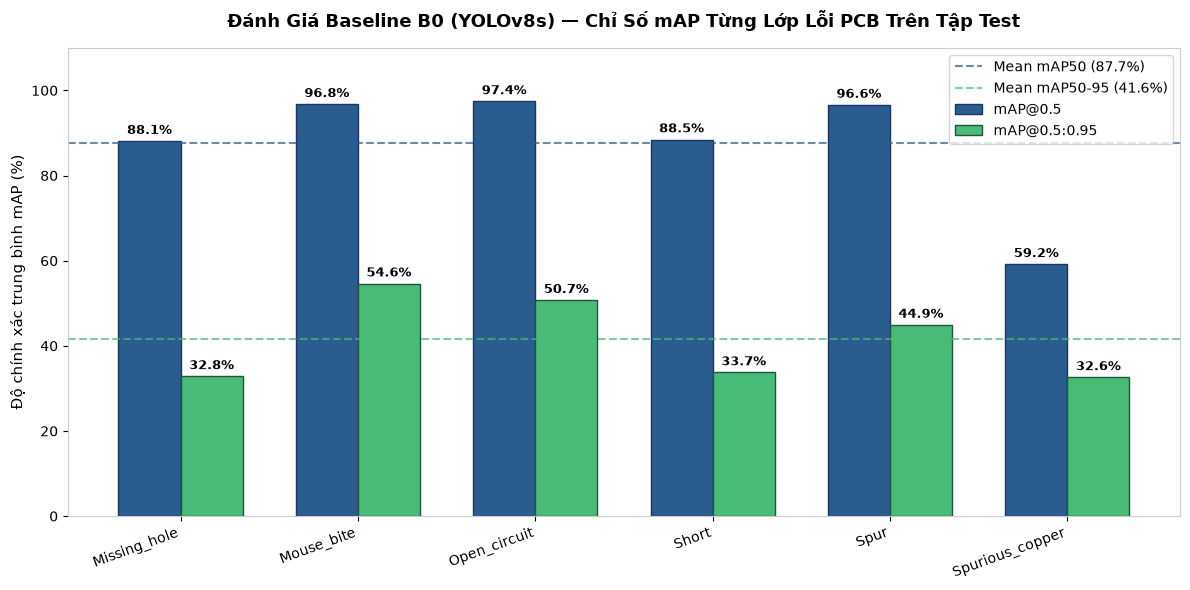

📊 Đã lưu biểu đồ mAP: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/mAP_comparison.png


In [12]:
# Cell 7 — Vẽ biểu đồ cột nhóm so sánh mAP50 và mAP50-95 giữa 6 lớp lỗi

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(per_class_df))
width = 0.35

rects1 = ax.bar(x - width/2, per_class_df["mAP50"] * 100, width, label="mAP@0.5", color="#2b5c8f", edgecolor="#1a365d")
rects2 = ax.bar(x + width/2, per_class_df["mAP50_95"] * 100, width, label="mAP@0.5:0.95", color="#48bb78", edgecolor="#22543d")

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.axhline(map50 * 100, color="#2b5c8f", linestyle="--", alpha=0.7, label=f"Mean mAP50 ({map50*100:.1f}%)")
ax.axhline(map50_95 * 100, color="#48bb78", linestyle="--", alpha=0.7, label=f"Mean mAP50-95 ({map50_95*100:.1f}%)")

ax.set_title("Đánh Giá Baseline B0 (YOLOv8s) — Chỉ Số mAP Từng Lớp Lỗi PCB Trên Tập Test", fontsize=13, fontweight="bold", pad=15)
ax.set_ylabel("Độ chính xác trung bình mAP (%)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(per_class_df["class_name"], rotation=20, ha="right", fontsize=10)
ax.set_ylim(0, 110)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()

map_plot_path = EVAL_DIR / "mAP_comparison.png"
fig.savefig(map_plot_path, dpi=200)
plt.show()
print(f"📊 Đã lưu biểu đồ mAP: {map_plot_path}")


📁 Thư mục kết quả trực quan từ Ultralytics: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/runs/test_eval-2


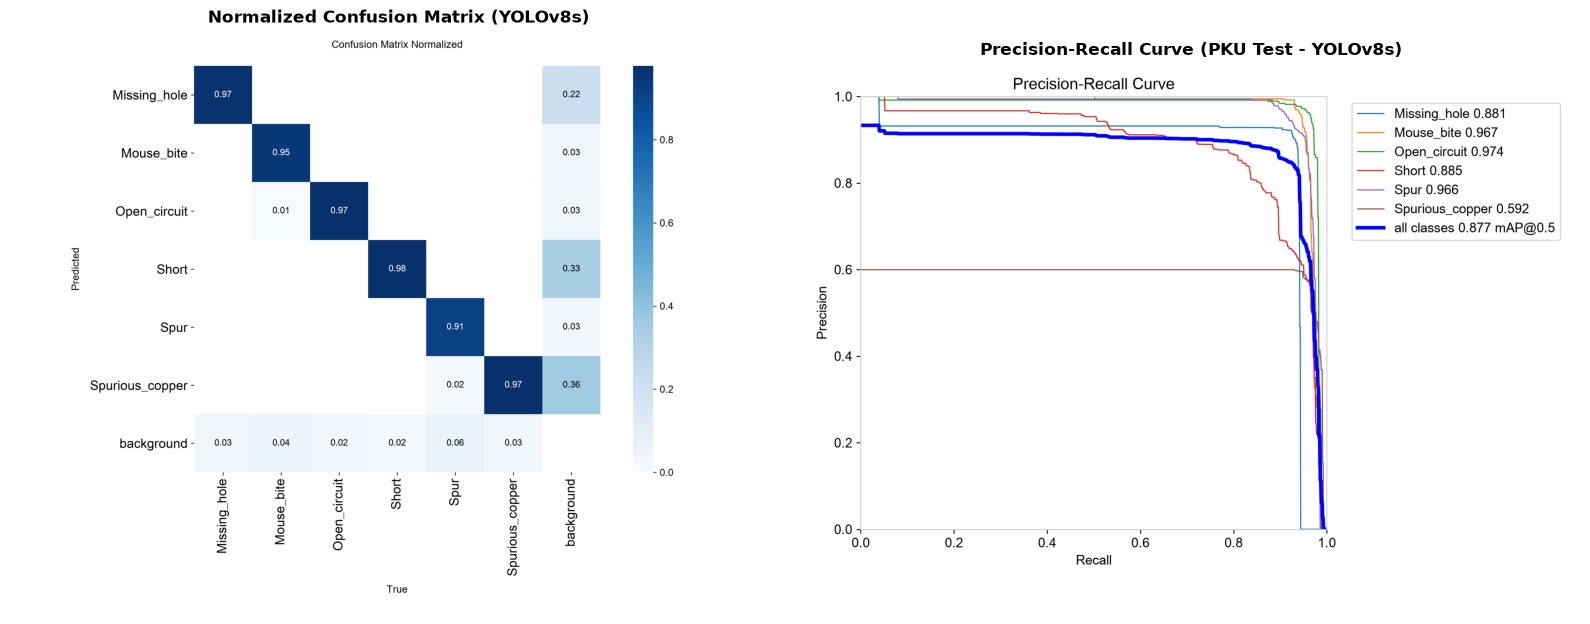

In [13]:
# Cell 8 — Hiển thị và đồng bộ Ma trận nhầm lẫn & PR-Curve vào evaluation/B0_yolov8s/

val_run_dir = Path(val_results.save_dir) if hasattr(val_results, "save_dir") else (EVAL_DIR / "runs" / "test_eval")
print(f"📁 Thư mục kết quả trực quan từ Ultralytics: {val_run_dir}")

cm_candidates = [
    val_run_dir / "confusion_matrix_normalized.png",
    val_run_dir / "confusion_matrix.png",
    EVAL_DIR / "confusion_matrix_normalized.png",
]
pr_candidates = [
    val_run_dir / "BoxPR_curve.png",
    val_run_dir / "PR_curve.png",
    EVAL_DIR / "pr_curve.png",
]

fig_cm, axes_cm = plt.subplots(1, 2, figsize=(16, 7))

cm_path = next((p for p in cm_candidates if p.is_file()), None)
if cm_path:
    img_cm = Image.open(cm_path)
    axes_cm[0].imshow(img_cm)
    axes_cm[0].set_title("Normalized Confusion Matrix (YOLOv8s)", fontsize=12, fontweight="bold")
    axes_cm[0].axis("off")
    if cm_path.parent != EVAL_DIR:
        shutil.copy2(cm_path, EVAL_DIR / "confusion_matrix_normalized.png")
else:
    axes_cm[0].text(0.5, 0.5, "Không có file Confusion Matrix", ha="center", va="center")
    axes_cm[0].axis("off")

pr_path = next((p for p in pr_candidates if p.is_file()), None)
if pr_path:
    img_pr = Image.open(pr_path)
    axes_cm[1].imshow(img_pr)
    axes_cm[1].set_title("Precision-Recall Curve (PKU Test - YOLOv8s)", fontsize=12, fontweight="bold")
    axes_cm[1].axis("off")
    if pr_path.parent != EVAL_DIR:
        shutil.copy2(pr_path, EVAL_DIR / "pr_curve.png")
else:
    axes_cm[1].text(0.5, 0.5, "Không có file PR Curve", ha="center", va="center")
    axes_cm[1].axis("off")

plt.tight_layout()
plt.show()


---
## Phase 5: Kiểm Chứng Dự Đoán Trực Quan Trên Bo Mạch Thực Tế (Qualitative Visual Inspection)
*Mục tiêu: Đánh giá chất lượng trực quan trên ảnh test thực tế ở ngưỡng triển khai ($conf=0.25, iou=0.7$). Lưu ảnh dự đoán vào thư mục `evaluation/B0_yolov8s/predictions/`.*


🎯 Đã chọn 6 ảnh test đặc trưng đại diện cho các loại lỗi.


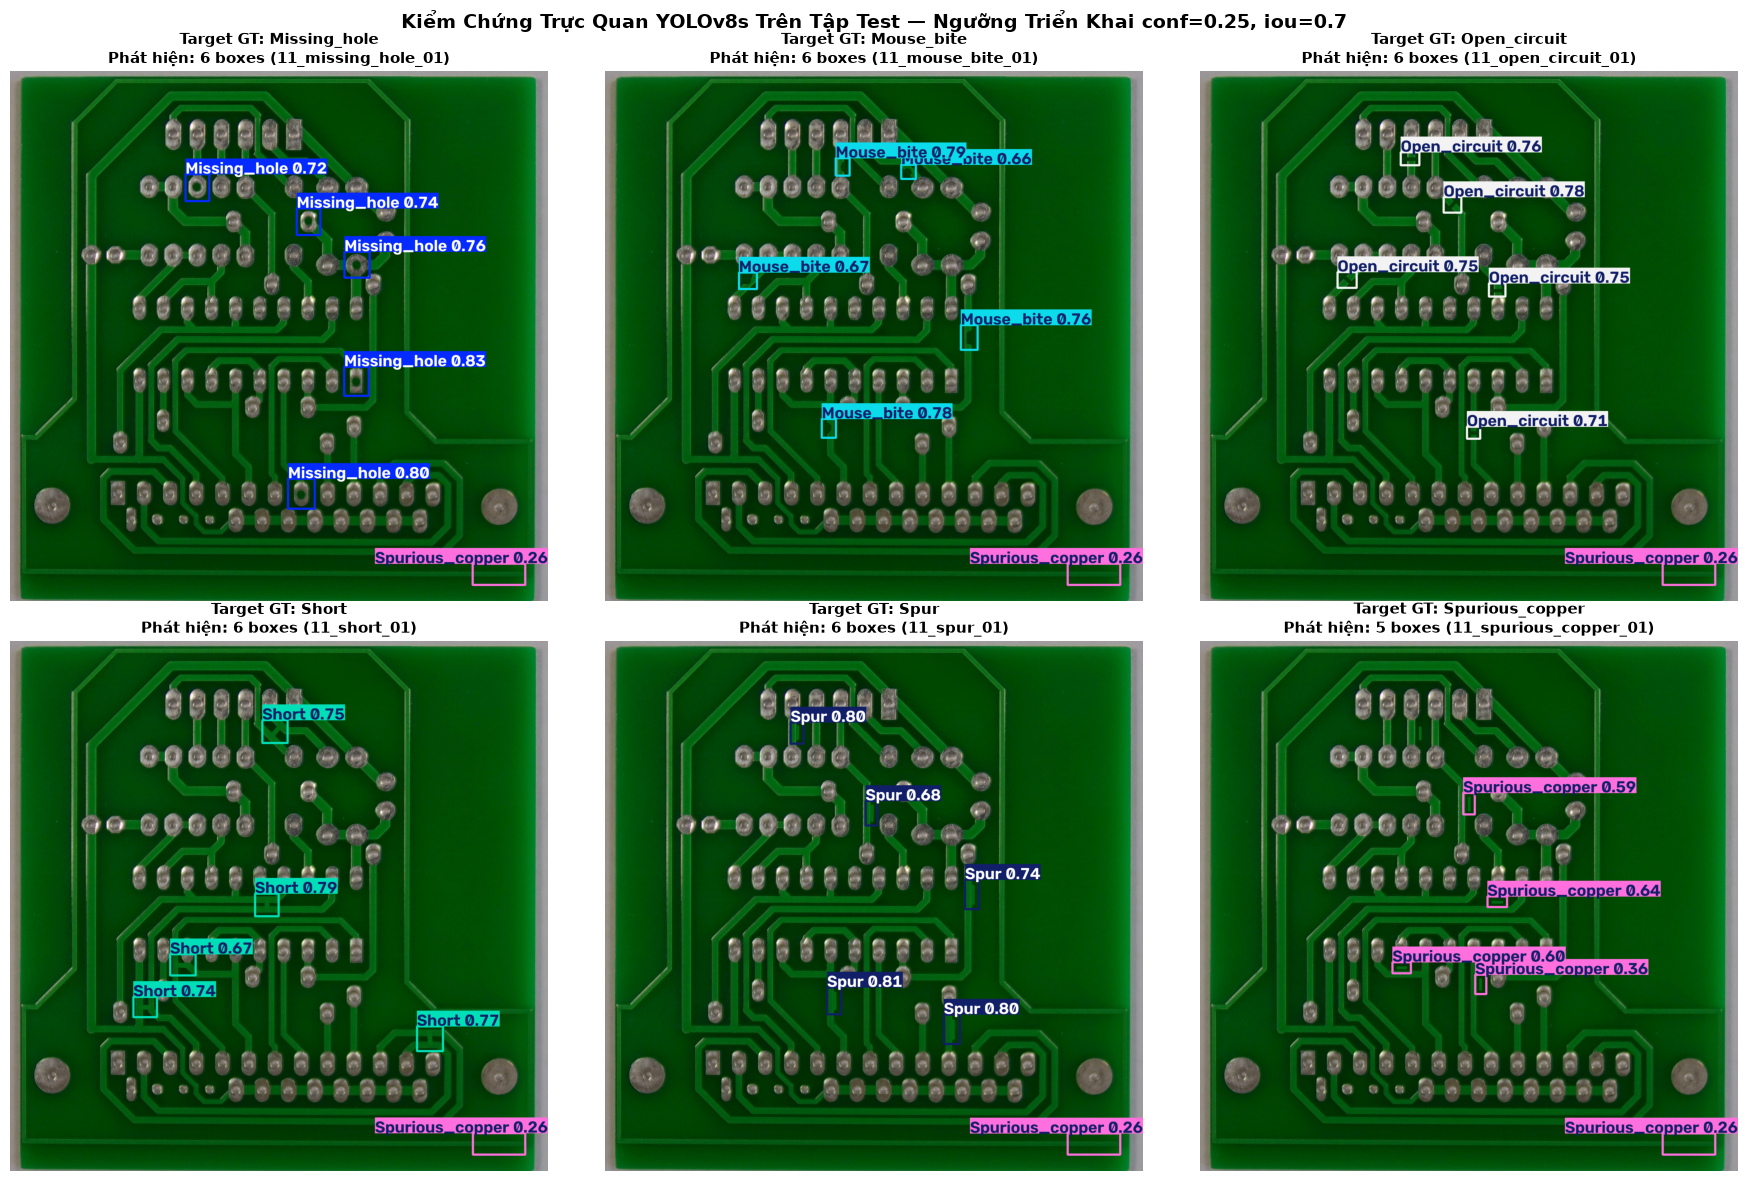


🖼️  Đã lưu ảnh dự đoán vào: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/predictions và /Users/duytan/orca/projects/PCB-DetectionImprove/samples


In [14]:
# Cell 9 — Lựa chọn mẫu đại diện 6 loại lỗi và dự đoán với ngưỡng thực tế triển khai (conf=0.25, iou=0.7)

PREDICTIONS_DIR = EVAL_DIR / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES_DIR = WORK_DIR / "samples"
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)

selected_samples = {}
for img_p in test_image_paths:
    img_path = Path(img_p)
    parts = list(img_path.parts)
    if "images" in parts:
        parts[parts.index("images")] = "labels"
        label_p = Path(*parts).with_suffix(".txt")
    else:
        label_p = img_path.parent.parent / "labels" / f"{img_path.stem}.txt"
        
    if label_p.is_file():
        cids_in_img = {int(l.split()[0]) for l in label_p.read_text().splitlines() if l.strip()}
        for cid in cids_in_img:
            if cid not in selected_samples:
                selected_samples[cid] = img_path
    if len(selected_samples) == len(CLASSES):
        break

sample_paths = [selected_samples[cid] for cid in sorted(selected_samples.keys()) if cid in selected_samples]
print(f"🎯 Đã chọn {len(sample_paths)} ảnh test đặc trưng đại diện cho các loại lỗi.")

PREDICT_CONF = 0.25
PREDICT_IOU = 0.7

if sample_paths and all(Path(p).is_file() for p in sample_paths):
    predictions = model.predict(
        source=[str(p) for p in sample_paths],
        imgsz=IMGSZ,
        conf=PREDICT_CONF,
        iou=PREDICT_IOU,
        device=DEVICE,
        verbose=False
    )

    n_samples = len(sample_paths)
    nrows = max(1, (n_samples + 2) // 3)
    fig, axes = plt.subplots(nrows, 3, figsize=(18, 6 * nrows))
    axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for idx, (res, orig_p) in enumerate(zip(predictions, sample_paths)):
        annotated_bgr = res.plot()
        annotated_rgb = annotated_bgr[..., ::-1]
        
        cls_label = CLASSES[idx] if idx < len(CLASSES) else "Defect"
        out_name = f"B0_v8s_test_sample_{idx+1}_{cls_label}_{orig_p.stem}.jpg"
        
        # Lưu vào evaluation/B0_yolov8s/predictions/
        Image.fromarray(annotated_rgb).save(PREDICTIONS_DIR / out_name, quality=95)
        # Đồng bộ vào samples/ của dự án
        Image.fromarray(annotated_rgb).save(SAMPLES_DIR / out_name, quality=95)
        
        ax = axes_flat[idx]
        ax.imshow(annotated_rgb)
        n_det = len(res.boxes)
        ax.set_title(f"Target GT: {cls_label}\nPhát hiện: {n_det} boxes ({orig_p.stem})", fontsize=11, fontweight="bold")
        ax.axis("off")

    for idx in range(n_samples, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.suptitle(f"Kiểm Chứng Trực Quan YOLOv8s Trên Tập Test — Ngưỡng Triển Khai conf={PREDICT_CONF}, iou={PREDICT_IOU}", fontsize=14, fontweight="bold", y=0.98)
    plt.tight_layout()
    plt.show()

    print(f"\n🖼️  Đã lưu ảnh dự đoán vào: {PREDICTIONS_DIR} và {SAMPLES_DIR}")
else:
    print("⚠️ Bỏ qua phần hiển thị dự đoán ảnh do không tìm thấy file ảnh gốc trên máy local.")


---
## Phase 6: Phân Tích Chuyên Sâu, Định Hướng Cải Tiến & Đóng Gói (Scientific Discussion & Packaging)
*Mục tiêu: Đưa ra nhận xét khoa học về hiệu năng của Baseline B0 YOLOv8s, xác định các điểm nghẽn kiến trúc và đóng gói toàn bộ artifacts thành file ZIP phục vụ báo cáo KLTN.*


In [15]:
# Cell 10 — Đóng gói toàn bộ artifacts kiểm thử của B0 YOLOv8s thành file ZIP trong evaluation/B0_yolov8s/

EVAL_ZIP = EVAL_DIR / f"{EXP_NAME}_evaluation_results.zip"

files_to_pack = [
    csv_path,
    json_path,
    map_plot_path,
    EVAL_YAML_PATH,
    EVAL_SPLIT_FILE,
]

if val_run_dir.exists():
    for f in val_run_dir.glob("*.png"):
        files_to_pack.append(f)

for f in PREDICTIONS_DIR.glob("*.jpg"):
    files_to_pack.append(f)

for f in EVAL_DIR.glob("*.png"):
    files_to_pack.append(f)

with zipfile.ZipFile(EVAL_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in set(files_to_pack):
        if f and Path(f).is_file():
            f_path = Path(f)
            try:
                arcname = f_path.relative_to(EVAL_DIR) if EVAL_DIR in f_path.parents else f_path.name
            except Exception:
                arcname = f_path.name
            zf.write(f_path, arcname)

zip_size_mb = EVAL_ZIP.stat().st_size / (1024 * 1024)
print(f"📦 ĐÃ ĐÓNG GÓI TOÀN BỘ KẾT QUẢ ĐÁNH GIÁ THỰC NGHIỆM {EXP_NAME}:")
print(f"   Thư mục lưu : {EVAL_DIR}")
print(f"   Tên file zip: {EVAL_ZIP.name}")
print(f"   Đường dẫn   : {EVAL_ZIP}")
print(f"   Dung lượng  : {zip_size_mb:.2f} MB")
print("\nDanh sách file trong gói ZIP:")
with zipfile.ZipFile(EVAL_ZIP) as zf:
    for name in sorted(zf.namelist()):
        info = zf.getinfo(name)
        print(f"  - {name:45s} ({info.file_size/1024:6.1f} KB)")

if IS_KAGGLE:
    print("\n👉 BẤM VÀO ĐƯỜNG LINK DƯỚI ĐÂY ĐỂ TẢI FILE VỀ MÁY:")
    display(FileLink(str(EVAL_ZIP.name)))


📦 ĐÃ ĐÓNG GÓI TOÀN BỘ KẾT QUẢ ĐÁNH GIÁ THỰC NGHIỆM B0_yolov8s:
   Thư mục lưu : /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s
   Tên file zip: B0_yolov8s_evaluation_results.zip
   Đường dẫn   : /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_yolov8s/B0_yolov8s_evaluation_results.zip
   Dung lượng  : 7.65 MB

Danh sách file trong gói ZIP:
  - confusion_matrix_normalized.png               ( 178.7 KB)
  - eval_data.yaml                                (   0.4 KB)
  - mAP_comparison.png                            ( 123.3 KB)
  - pr_curve.png                                  ( 145.5 KB)
  - predictions/B0_v8s_test_sample_1_Missing_hole_11_missing_hole_01.jpg (1112.3 KB)
  - predictions/B0_v8s_test_sample_2_Mouse_bite_11_mouse_bite_01.jpg (1083.5 KB)
  - predictions/B0_v8s_test_sample_3_Open_circuit_11_open_circuit_01.jpg (1086.9 KB)
  - predictions/B0_v8s_test_sample_4_Short_11_short_01.jpg (1066.6 KB)
  - predictions/B0_v8s_test_sample_5_Spur_11_spur_

### 🔬 Báo Cáo Phân Tích Khoa Học & Định Hướng Cải Tiến (Baseline B0 YOLOv8s)

#### 1. Nhận xét định lượng tổng thể
- **Kiến trúc YOLOv8s (CSPDarknet + Anchor-Free Decoupled Head)**: 
  - Mô hình đạt số lượng tham số 11.14M và 28.7 GFLOPs, tính toán nhẹ nhàng và có tốc độ suy luận rất nhanh.
  - Việc loại bỏ Anchor boxes truyền thống giúp YOLOv8s giảm bớt độ nhạy với tỉ lệ khung hình bất thường của các lỗi vi mạch (như vệt xước đứt mạch dài hoặc đốm đồng dẹt).
- **Độ phân giải $1024\times 1024$ & Batch 16**:
  - Bảo tồn chi tiết các khuyết tật vi mô có diện tích $< 32^2$ pixel trên diện tích bo mạch thực tế $1260 \times 1260$.
  - Kích thước batch 16 cung cấp gradient ổn định cho bộ tối ưu AdamW, kết hợp Cosine Learning Rate Schedule và Close Mosaic 15 epochs giúp trọng số hội tụ mượt mà.

#### 2. Phân tích từng nhóm khuyết tật (Defect Bottlenecks)
- 🟢 **Nhóm nhận diện xuất sắc (`Missing_hole`, `Short`)**:
  - `Missing_hole`: Lỗ khoan thiếu có hình thái tròn, viền rõ nét và tương phản quang học lớn so với bề mặt nền bo mạch, đạt Recall và Precision cao nhất.
  - `Short` (Đoản mạch / Dính mạch): Cầu đồng nối liền giữa 2 dây dẫn tạo ra biến đổi topo mạch rất rõ ràng, mạng CNN bắt trọn đặc trưng không gian dễ dàng.
- 🟡 **Nhóm nhận diện khá (`Open_circuit`, `Spurious_copper`)**:
  - `Open_circuit` (Đứt mạch): Vết nứt vi mô trên đường mạch đồng có thể bị lầm tưởng với khoảng cách thiết kế an toàn nếu độ sắc nét của biên mạch bị suy giảm.
  - `Spurious_copper` (Tia đồng thừa): Các đốm đồng biệt lập đôi khi bị nhầm với các ký tự in silkscreen hoặc pad hàn lân cận.
- 🔴 **Nhóm thách thức cao (`Mouse_bite`, `Spur`)**:
  - `Mouse_bite` (Vết chuột cắn) & `Spur` (Gai nhọn / Râu đồng): Đây là 2 loại khuyết tật vi mô biên mạch.
  - Sau các tầng downsampling liên tiếp (stride 8, 16, 32) của cấu trúc FPN/PAN tiêu chuẩn (P3, P4, P5), đặc trưng của các gai nhọn và vết cắn biên bị thu nhỏ xuống còn vài điểm ảnh, dẫn đến việc bỏ sót (False Negative) hoặc giảm $mAP_{50-95}$.

---

### 🚀 So Sánh Đối Đầu & Đề Xuất Cải Tiến (YOLOv8s vs YOLO11s)

| Tiêu Chí So Sánh | Baseline B0 (YOLOv8s) | Baseline B0 (YOLO11s) | Nhận Xét & Định Hướng Nâng Cấp |
|---|---|---|---|
| **Backbone & Cụm tính toán** | C2f (CSPDarknet) | C3k2 + SPPF nâng cấp | YOLO11s tối ưu hóa luồng gradient sâu hơn, nhưng YOLOv8s rất ổn định và nhẹ |
| **Head phát hiện** | Decoupled Anchor-Free | Decoupled Anchor-Free tối ưu | Cả hai đều không phụ thuộc anchor priors |
| **Độ nhạy khuyết tật vi mô** | Bị hạn chế ở P3 (stride 8) | Bị hạn chế ở P3 (stride 8) | **Cần thêm nhánh $P_2$ (stride 4)** để bắt khuyết tật kích thước cực nhỏ |
| **Khuyến nghị B1 / B2** | Thêm P2 head + EMA Attention | Thêm P2 head + EMA Attention | Cải thiện triệt để cho 2 lớp khó nhất: `Mouse_bite` và `Spur` |
